# Step 03: What the teacher told us about our labels

We asked a large model (the **teacher**, `gpt-4.1`) to label 1,840 tickets using our written
guidelines. This notebook reads those labels and answers one question at a time. Each section ends
with the decision it supports.

**The decision this notebook builds up to:** retire `hr` as a separate category and merge it into
`customer_service`. The 38 HR tickets are kept as examples; only the label changes.

| # | Question | Decision it feeds |
|---|---|---|
| 1 | What did the teacher label in the 50-ticket pilot? | Is something off with the label mix? |
| 2 | Which categories did it use across all labelled tickets? | Do all 6 categories have enough examples? |
| 3 | Is the teacher wrong, or are the dataset's own labels wrong? | Can we trust the dataset queues as truth? |
| 4 | Did searching for more rare tickets work? | Can we fix the shortage by labelling more? |
| 5 | Where do genuine HR tickets live, and how many exist? | Is `hr` a real category in this data? |
| 6 | Can we even measure `hr` on a test set? | Would an `hr` score mean anything? |
| 7 | Keep, merge or delete? | The thought process and the decision |
| 8 | What do the labels look like after the merge? | What we train on |

Everything here reads local files. Running this notebook makes **no** API calls and costs nothing.

## 0. Load the data

In [1]:
import collections
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent  # this notebook lives in notebooks/, so the project is one level up
CATEGORIES = ["technical", "product", "billing", "customer_service", "outage", "hr"]


def read_jsonl(path):
    rows = []
    with open(path, encoding="utf-8") as file:
        for line in file:
            rows.append(json.loads(line))
    return rows


# Every ticket (text + the dataset's own queue/labels), looked up by its id.
tickets = {}
for name in ["val", "train", "train_extra", "train_extra2", "test"]:
    for row in read_jsonl(ROOT / "data" / "processed" / f"{name}.jsonl"):
        tickets[row["id"]] = row

# The labels the teacher produced, one list per labelling run.
val_labels = read_jsonl(ROOT / "data" / "labeled" / "val__gpt-4.1.jsonl")
train_labels = read_jsonl(ROOT / "data" / "labeled" / "train__gpt-4.1.jsonl")
extra1_labels = read_jsonl(ROOT / "data" / "labeled" / "train_extra__gpt-4.1.jsonl")
extra2_labels = read_jsonl(ROOT / "data" / "labeled" / "train_extra2__gpt-4.1.jsonl")


def count_categories(labelled_rows):
    counts = collections.Counter()
    for row in labelled_rows:
        counts[row["label"]["category"]] += 1
    return counts


print("validation:", len(val_labels))
print("training (random 1,000):", len(train_labels))
print("mined round 1:", len(extra1_labels))
print("mined round 2:", len(extra2_labels))

validation: 300
training (random 1,000): 1000
mined round 1: 500
mined round 2: 40


## 1. The pilot: what did the teacher label in the first 50 tickets?

In [2]:
pilot = val_labels[:50]  # the first 50 labelled tickets were the pilot
pilot_counts = count_categories(pilot)
for category in CATEGORIES:
    print(f"{category:18} {pilot_counts[category]}")

technical          34
product            16
billing            0
customer_service   0
outage             0
hr                 0


**What we see:** only `technical` and `product` appear. Four of the six categories got zero tickets.

**Why that was a warning sign:** the validation set follows the dataset's natural mix, where the
dataset says about 24% of tickets are customer service and 10% are billing. Seeing none of them in
50 tickets is very unlikely by chance. Either the teacher is biased, or the dataset's labels do not
match what the tickets say. Sections 2 and 3 find out which.

## 2. Which categories did the teacher use across everything?

In [3]:
sets = {
    "val (300)": val_labels,
    "train (1,000)": train_labels,
    "mined round 1 (500)": extra1_labels,
    "mined round 2 (40)": extra2_labels,
}
table = {}
for set_name in sets:
    counts = count_categories(sets[set_name])
    numbers = []
    for category in CATEGORIES:
        numbers.append(counts[category])
    table[set_name] = numbers

distribution = pd.DataFrame(table, index=CATEGORIES)
distribution

,val (300),"train (1,000)",mined round 1 (500),mined round 2 (40)
technical,154,397,45,6
product,119,394,269,29
billing,13,74,68,0
customer_service,2,19,95,1
outage,11,102,3,0
hr,1,14,20,4


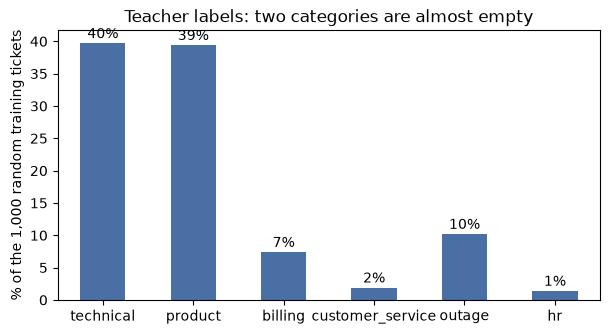

In [4]:
train_percent = distribution["train (1,000)"] / 10  # 1,000 tickets, so count / 10 = percent
ax = train_percent.plot.bar(color="#4a6fa5", figsize=(7, 3.5))
ax.set_ylabel("% of the 1,000 random training tickets")
ax.set_title("Teacher labels: two categories are almost empty")
for i, value in enumerate(train_percent):
    ax.text(i, value + 0.8, f"{value:.0f}%", ha="center")
plt.xticks(rotation=0)
plt.show()

**What we see (random 1,000 training tickets):** `technical` 40% and `product` 39% make up almost
four in five tickets. `customer_service` is 2% (19 tickets) and `hr` is 1% (14 tickets).

**Why it matters:** a small model cannot learn a category from 14 or 19 examples. If we do nothing,
it will simply never predict them.

## 3. Is the teacher wrong, or are the dataset's labels wrong?

Teacher agrees with the dataset on 477 of 1300 tickets (37%)


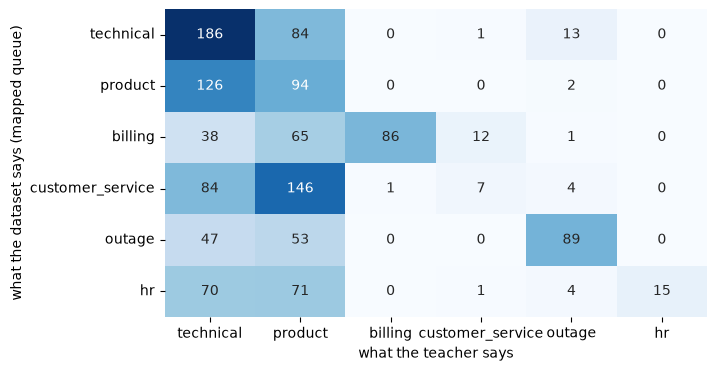

In [5]:
# Use only tickets we did NOT pick with keywords, so this is a fair sample.
fair_rows = val_labels + train_labels

pairs = []
agree = 0
for row in fair_rows:
    dataset_category = tickets[row["id"]]["dataset_category"]
    teacher_category = row["label"]["category"]
    pairs.append({"dataset": dataset_category, "teacher": teacher_category})
    if dataset_category == teacher_category:
        agree = agree + 1

pairs_table = pd.DataFrame(pairs)
confusion = pd.crosstab(pairs_table["dataset"], pairs_table["teacher"])
confusion = confusion.reindex(index=CATEGORIES, columns=CATEGORIES, fill_value=0)

print(f"Teacher agrees with the dataset on {agree} of {len(fair_rows)} tickets ({agree / len(fair_rows):.0%})")
plt.figure(figsize=(7, 4))
sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.ylabel("what the dataset says (mapped queue)")
plt.xlabel("what the teacher says")
plt.show()

In [6]:
# Read some of the disagreements ourselves: tickets the dataset calls customer_service,
# but the teacher calls technical or product.
random.seed(3)
disagreements = []
for row in fair_rows:
    dataset_category = tickets[row["id"]]["dataset_category"]
    if dataset_category == "customer_service" and row["label"]["category"] in ["technical", "product"]:
        disagreements.append(row)

dataset_cs_total = int(confusion.loc["customer_service"].sum())
print(f"{len(disagreements)} of {dataset_cs_total} dataset-customer_service tickets were labelled technical/product\n")
for row in random.sample(disagreements, 5):
    text = tickets[row["id"]]["text"][:200].replace("\n", " ")
    print("teacher says:", row["label"]["category"], "|", text)
    print()

230 of 242 dataset-customer_service tickets were labelled technical/product

teacher says: technical | Problem with QuickBooks Integration  Our project management SaaS is facing integration difficulties with QuickBooks Online. Users are unable to sync financial data correctly due to recent API modifica

teacher says: product | Health Care Assistance  Customer Support, I am reaching out to inquire about the security protocols in place to safeguard patient information within healthcare solutions. Could you please provide deta

teacher says: product | Seeking comprehensive documentation for integrating PostgreSQL into a project management SaaS solution. Would greatly appreciate detailed, step-by-step instructions and any pertinent resources that co

teacher says: product | Enhancing Investment Techniques with MATLAB  Would appreciate detailed information on how to optimize investment techniques using MATLAB R2021a data analytics services to potentially enhance returns?

teacher says: tech

**What we see:** the teacher disagrees with the dataset on most tickets, and almost every
`customer_service` ticket in the dataset is read as `technical` or `product`. The examples above are
hospital data breaches, system crashes and security questions. Those are technical problems whatever
queue they were filed in.

**Conclusion:** the teacher is following our guidelines and reading the ticket text. The dataset's
queue labels are mostly unrelated to the text. This confirms the label-noise worry from ADR-010, and
it means there simply are not many true `customer_service` or `hr` tickets in this data.

## 4. Did searching for more rare tickets work?

To fix the shortage we searched the unused tickets for HR-like and service-like words
(`scripts/03_mine_rare_classes.py`), had the teacher label the best matches, and counted how many it
confirmed as the category we were hoping for. Round 2 used a stricter HR word list built from the
tickets round 1 confirmed.

In [7]:
runs = [
    ("round 1", "hr", extra1_labels),
    ("round 1", "customer_service", extra1_labels),
    ("round 2", "hr", extra2_labels),
]
yield_rows = []
for round_name, wanted, labelled in runs:
    picked = 0
    confirmed = 0
    for row in labelled:
        if tickets[row["id"]]["mined_for"] == wanted:
            picked = picked + 1
            if row["label"]["category"] == wanted:
                confirmed = confirmed + 1
    yield_rows.append({
        "round": round_name,
        "searched for": wanted,
        "tickets labelled": picked,
        "teacher confirmed": confirmed,
        "hit rate": f"{confirmed / picked:.0%}",
    })

pd.DataFrame(yield_rows)

,round,searched for,tickets labelled,teacher confirmed,hit rate
0,round 1,hr,200,20,10%
1,round 1,customer_service,300,90,30%
2,round 2,hr,40,4,10%


**What we see:** `customer_service` searching worked reasonably (about a third of picks confirmed), so
that category went from 19 to over 100 examples. `hr` searching did not: 10% in round 1, 10% in
round 2, and the strict list only matched 40 unused tickets before running out.

**Conclusion:** we cannot fix `hr` by labelling more. The search ran out of candidates. Section 5
shows why.

## 5. Where do genuine HR tickets live, and how many exist?

In [8]:
hr_rows = []
for labelled in [val_labels, train_labels, extra1_labels, extra2_labels]:
    for row in labelled:
        if row["label"]["category"] == "hr":
            hr_rows.append(row)

queue_counts = collections.Counter()
for row in hr_rows:
    queue_counts[tickets[row["id"]]["queue"]] += 1

print(len(hr_rows), "tickets the teacher labelled hr. Which dataset queue were they in?")
print(dict(queue_counts))

39 tickets the teacher labelled hr. Which dataset queue were they in?
{'Human Resources': 39}


In [9]:
# The 1,000 training tickets are a random sample of the training file, so we can use them
# to estimate how often a ticket from the dataset's HR queue is genuinely HR.
sample_hr_queue = 0
sample_confirmed = 0
for row in train_labels:
    if tickets[row["id"]]["queue"] == "Human Resources":
        sample_hr_queue = sample_hr_queue + 1
        if row["label"]["category"] == "hr":
            sample_confirmed = sample_confirmed + 1

rate = sample_confirmed / sample_hr_queue

hr_queue_total = 0
for row in read_jsonl(ROOT / "data" / "raw" / "tickets_en.jsonl"):
    if row["queue"] == "Human Resources":
        hr_queue_total = hr_queue_total + 1

print(f"In the random sample: {sample_hr_queue} HR-queue tickets, {sample_confirmed} were genuine HR ({rate:.0%})")
print(f"HR-queue tickets in the whole dataset: {hr_queue_total}")
print(f"Estimated genuine HR tickets in the whole dataset: about {rate * hr_queue_total:.0f}")
print(f"Found so far: {len(hr_rows)}")

In the random sample: 155 HR-queue tickets, 14 were genuine HR (9%)
HR-queue tickets in the whole dataset: 459
Estimated genuine HR tickets in the whole dataset: about 41
Found so far: 39


In [10]:
# What are the genuine HR tickets about? Count the most common words.
stop_words = {"support", "customer", "please", "would", "could", "about", "which", "their",
              "there", "these", "regarding", "assistance", "information", "issue", "problem",
              "dear", "hello", "team", "request", "provide", "additionally", "appreciate"}
word_counts = collections.Counter()
for row in hr_rows:
    text = tickets[row["id"]]["text"].lower()
    cleaned = ""
    for character in text:
        if character.isalpha():
            cleaned = cleaned + character
        else:
            cleaned = cleaned + " "
    for word in set(cleaned.split()):  # set(): count each word once per ticket
        if len(word) > 4 and word not in stop_words:
            word_counts[word] += 1

print(word_counts.most_common(15))

[('employee', 31), ('training', 14), ('employees', 10), ('recent', 10), ('specific', 9), ('software', 9), ('departments', 9), ('available', 9), ('onboarding', 9), ('roles', 8), ('responsibilities', 8), ('details', 8), ('processing', 8), ('forward', 8), ('company', 8)]


**What we see:**
- Every genuine HR ticket came from the dataset's own *Human Resources* queue. None were hiding in
  other queues, so a smarter keyword search has nowhere new to look.
- Only a small share of that queue is genuinely HR (the rate printed above). The rest are ordinary
  technical or product tickets with an HR label.
- The genuine ones repeat a few themes: employee training, onboarding, roles and responsibilities,
  plus payroll delays, turnover and remote-work policy (see the common words above).

**Conclusion:** there are only about 40 to 45 real HR tickets in the whole dataset, and we have
already found 39 of them. More labelling would not give more.

## 6. Could we measure `hr` on a test set?

The test set (500) was sampled **by the dataset's labels**, before we knew they were noisy. So its
"hr" tickets are really HR-queue tickets, and only a small share of those are genuine HR.

In [11]:
test_hr_queue = 0
gold_hr_queue = 0
for ticket in tickets.values():
    if "gold" in ticket and ticket["dataset_category"] == "hr":  # only test.jsonl rows have "gold"
        test_hr_queue = test_hr_queue + 1
        if ticket["gold"]:
            gold_hr_queue = gold_hr_queue + 1

print(f"HR-queue tickets in the test set: {test_hr_queue}, in the 200-ticket gold set: {gold_hr_queue}")
print(f"Expected GENUINE hr tickets in the test set: about {test_hr_queue * rate:.1f}")
print(f"Expected GENUINE hr tickets in the gold set: about {gold_hr_queue * rate:.1f}")

HR-queue tickets in the test set: 10, in the 200-ticket gold set: 4
Expected GENUINE hr tickets in the test set: about 0.9
Expected GENUINE hr tickets in the gold set: about 0.4


In [12]:
def wilson_range(successes, total):
    # 95% range for a measured success rate, given how few tickets we measured on.
    z = 1.96
    p = successes / total
    centre = (p + z * z / (2 * total)) / (1 + z * z / total)
    spread = z * ((p * (1 - p) / total + z * z / (4 * total * total)) ** 0.5) / (1 + z * z / total)
    return round(centre - spread, 2), round(centre + spread, 2)


# Suppose the model gets about 70% of hr tickets right. What would our test score look like?
rows = []
for n in [1, 3, 10, 30]:
    successes = round(0.7 * n)
    low, high = wilson_range(successes, n)
    rows.append({"hr tickets in test": n, "measured score": f"{successes}/{n}", "true score could be anywhere in": f"{low:.0%} to {high:.0%}"})
pd.DataFrame(rows)

,hr tickets in test,measured score,true score could be anywhere in
0,1,1/1,21% to 100%
1,3,2/3,21% to 94%
2,10,7/10,40% to 89%
3,30,21/30,52% to 83%


**What we see:** the test set will hold roughly one genuine HR ticket. With so few, a measured score
tells us nothing: one ticket flips it between 0% and 100%. Even 10 tickets leave the true score
somewhere between about 40% and 90%.

**A correction to something I said earlier:** I said the test set would have "about 10" HR tickets.
That counted the dataset's HR queue. The genuine HR count is far smaller, about one.

**Why this matters beyond `hr`:** the final report averages scores across categories (macro-F1). A
category with one test ticket adds pure noise to that average.

## 7. Keep, merge or delete? The thought process

We asked five questions, in this order.

**1. Can the model learn `hr`?** With 38 examples, about 2% of training, no. It would be near-random.

**2. Can we get more examples?** No. The dataset holds roughly 40 to 45 genuine HR tickets and we
have found almost all of them (section 5).

**3. Can we measure it?** No. The test set has about one genuine HR ticket (section 6).

**4. What is lost by each option?**

| Option | What happens to the 38 HR tickets | Risk | Verdict |
|---|---|---|---|
| **Keep `hr`** | Stay as `hr` | Model ignores the category; its score is noise and drags the average | Rejected: we could not tell good from bad |
| **Delete `hr`** (drop those tickets) | Thrown away | A real payroll ticket then has no right answer and gets forced into the wrong category | Rejected: loses information |
| **Merge `hr` into `customer_service`** | Kept as examples of `customer_service` | The definition gets slightly broader | **Chosen** |
| Merge into a new `other` | Kept | A catch-all category is easy to over-predict | Not needed: `customer_service` already covers "not a technical fault" |

**5. Is it reversible?** Yes. The teacher's original labels stay in `data/labeled/`; the merge is a
mapping applied afterwards. If real traffic turns out to contain many HR tickets, we collect more
and bring `hr` back as a category.

**Decision:** merge `hr` into `customer_service`. This goes in as an amendment to ADR-010, with the
schema moving to v1.1 (5 categories) and the `customer_service` definition widened.

**What would change our mind:** real tickets showing HR above roughly 5% of traffic, or a different
dataset with a few hundred genuine HR tickets.

## 8. After the merge: what do we train on?

In [13]:
before = collections.Counter()
after = collections.Counter()
for labelled in [train_labels, extra1_labels, extra2_labels]:
    for row in labelled:
        category = row["label"]["category"]
        before[category] += 1
        if category == "hr":
            category = "customer_service"
        after[category] += 1

total = sum(after.values())
rows = []
for category in CATEGORIES:
    rows.append({
        "category": category,
        "before merge": before[category],
        "after merge": after[category],
        "share after": f"{after[category] / total:.0%}" if after[category] else "-",
    })
pd.DataFrame(rows)

,category,before merge,after merge,share after
0,technical,448,448,29%
1,product,692,692,45%
2,billing,142,142,9%
3,customer_service,115,153,10%
4,outage,105,105,7%
5,hr,38,0,-


In [14]:
from triage.prompts import CATEGORY_DEFINITIONS
from triage.schema import Category

print("Current customer_service definition:")
print("  ", CATEGORY_DEFINITIONS[Category.CUSTOMER_SERVICE])
print()
print("Current hr definition:")
print("  ", CATEGORY_DEFINITIONS[Category.HR])
print()
print("Proposed (hr folded in):")
print("   account changes, orders, returns/exchanges, pre-sales and pricing questions, general")
print("   enquiries, internal employee matters (payroll, onboarding, leave, staff policies),")
print("   and complaints that are not a technical fault")

Current customer_service definition:
   account changes, orders, returns/exchanges, pre-sales and pricing questions, general enquiries, complaints that are not a technical fault

Current hr definition:
   employee matters: payroll, leave, onboarding, internal staff policies

Proposed (hr folded in):
   account changes, orders, returns/exchanges, pre-sales and pricing questions, general
   enquiries, internal employee matters (payroll, onboarding, leave, staff policies),
   and complaints that are not a technical fault


**What we see:** `customer_service` grows from 115 to 153 examples (about 10% of training), a size a
small model can learn. Five categories remain.

## Summary

| Finding | Evidence |
|---|---|
| The teacher reads the text; the dataset's queues mostly do not | Section 3: low agreement, and the disagreements read as technical problems |
| `technical` and `product` dominate (about 75%) | Section 2 |
| `customer_service` was fixable by searching; `hr` was not | Section 4 |
| Only about 40 to 45 genuine HR tickets exist, nearly all found | Section 5 |
| `hr` cannot be measured (about 1 test ticket) | Section 6 |
| **Merge `hr` into `customer_service`** | Section 7 |

## Next steps
- [ ] Amend ADR-010 (5 categories) and add an ADR for the rare-class mining and the merge
- [ ] Bump `SCHEMA_VERSION` to 1.1, remove `HR` from the `Category` enum
- [ ] Widen the `customer_service` definition in `src/triage/prompts.py`
- [ ] Write the merged labels to `data/processed/` for Step 04
- [ ] Update the Step 03 guide and ADR-005 (the teacher is Azure `gpt-4.1`, not Gemini)